# TP Integrador — Dataset Nursery

In [21]:
# @title Imports y parámetros
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# carpeta raíz del proyecto (funciona sin importar desde dónde se ejecute el notebook)
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "datos.py").exists())
RUTA_DATOS = RAIZ / "data" / "raw" / "Datos.txt"

# para poder importar desde src/
sys.path.append(str(RAIZ / "src"))
from datos import cargar_datos
import AA_utils

SEMILLA = 42  # para que los resultados sean reproducibles

In [23]:
# @title Cargar dataset
columnas= ['parents', 'has_nurs', 'form', 'children', 'housing', 'finance', 'social', 'health', 'clase']
df= pd.read_csv(RUTA_DATOS, header=None, names=columnas, dtype=str)

print(f"Cantidad de registros: {df.shape[0]}")
print(f"Cantidad de columnas: {df.shape[1]}")
print("\nValores nulos por columna:")
print(df.isnull().sum())

display(df.head())
display(df.describe())   # count / unique / top / freq de cada atributo (todos son nominales)

Cantidad de registros: 12960
Cantidad de columnas: 9

Valores nulos por columna:
parents     0
has_nurs    0
form        0
children    0
housing     0
finance     0
social      0
health      0
clase       0
dtype: int64


,parents,has_nurs,form,children,housing,finance,social,health,clase
0,usual,proper,complete,1,convenient,convenient,nonprob,recommended,recommend
1,usual,proper,complete,1,convenient,convenient,nonprob,priority,priority
2,usual,proper,complete,1,convenient,convenient,nonprob,not_recom,not_recom
3,usual,proper,complete,1,convenient,convenient,slightly_prob,recommended,recommend
4,usual,proper,complete,1,convenient,convenient,slightly_prob,priority,priority


,parents,has_nurs,form,children,housing,finance,social,health,clase
count,12960,12960,12960,12960,12960,12960,12960,12960,12960
unique,3,5,4,4,3,2,3,3,5
top,usual,proper,complete,1,convenient,convenient,nonprob,recommended,not_recom
freq,4320,2592,3240,3240,4320,6480,4320,4320,4320


### Qué vemos en la carga

- Hay 12.960 registros y 9 columnas (8 atributos más `clase`), sin valores nulos.
- En los 8 atributos, la `freq` del valor más frecuente es exactamente 12.960 / `unique`: cada valor aparece la misma cantidad de veces.
- El producto de los `unique` de los atributos da 3·5·4·4·3·2·3·3 = 12.960, igual que la cantidad de registros. Coincide con la descripción del dataset: las instancias cubren todo el espacio de atributos, cada combinación una vez.
- Por eso ningún atributo está desbalanceado, y lo que hay que analizar es cómo se relaciona cada uno con la clase.
- `clase` es la única variable despareja: tiene 5 valores y `not_recom` aparece 4.320 veces, cuando un reparto parejo daría 2.592.

In [24]:
# @title Distribución de la clase
print(df['clase'].value_counts())

fig= px.histogram(df, x='clase', title='Distribución de la clase (dataset completo)',
                  category_orders={'clase': df['clase'].value_counts().index.tolist()})
fig.show()

clase
not_recom     4320
priority      4266
spec_prior    4044
very_recom     328
recommend        2
Name: count, dtype: int64


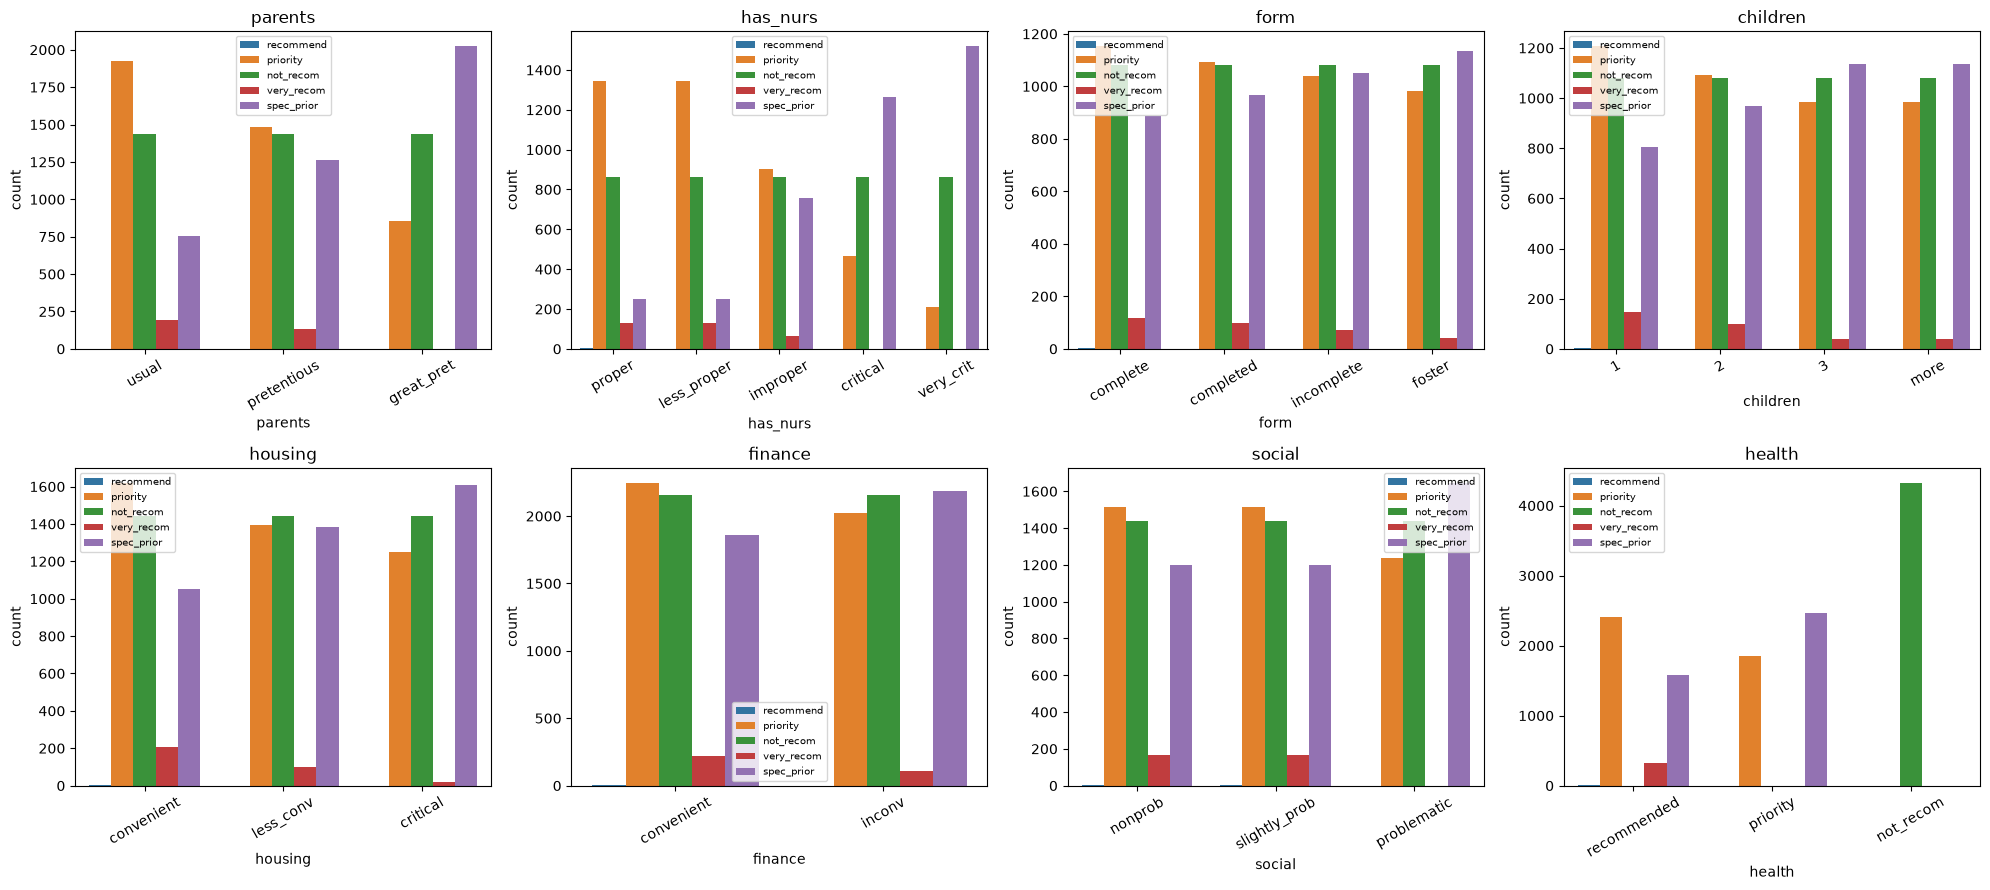

In [26]:
# @title Distribución de cada atributo según la clase
fig, axes= plt.subplots(2, 4, figsize=(20, 9))
for col, ax in zip(columnas[:-1], axes.ravel()):
    sns.countplot(data=df, x=col, hue='clase', ax=ax)
    ax.set_title(col)
    ax.tick_params(axis='x', rotation=30)
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

In [27]:
# @title ¿Por qué no usar la clase "not_recom"?
# Tabla cruzada entre el atributo health y la clase
tabla= pd.crosstab(df['health'], df['clase'])
display(tabla)
fig= px.imshow(tabla, text_auto=True, color_continuous_scale='Blues',
               title='health vs clase')
fig.show()
# Las 4320 muestras con health = not_recom son EXACTAMENTE las de la clase not_recom.
# Un único atributo separa perfectamente esa clase: el problema not_recom vs very_recom
# sería trivial (100% de acierto). Por eso se elige la siguiente clase mayoritaria: "priority"

clase,not_recom,priority,recommend,spec_prior,very_recom
health,,,,,
not_recom,4320,0,0,0,0
priority,0,1854,0,2466,0
recommended,0,2412,2,1578,328


### Qué vemos en el cruce de `health` con la clase

- Las 4.320 filas con `health = not_recom` son exactamente las 4.320 de la clase `not_recom`. Esa clase queda definida por una sola columna.
- Si comparáramos `not_recom` contra `very_recom`, cualquier modelo separaría todo con esa regla y no habría nada que comparar.
- `very_recom` solo aparece con `health = recommended`.
- Por eso elegimos `priority` como clase mayoritaria: no queda definida por un único atributo y comparte `health = recommended` con `very_recom` (2.412 filas de `priority` y 328 de `very_recom`).

In [28]:
# @title Selección del subconjunto
df_bin= df[df['clase'].isin(['priority', 'very_recom'])].copy()

print(f"Cantidad de registros: {df_bin.shape[0]}")
print(df_bin['clase'].value_counts())
print(f"\nRelación de desbalance: {(df_bin['clase']=='priority').sum() / (df_bin['clase']=='very_recom').sum():.1f} a 1")

fig= px.histogram(df_bin, x='clase', title='Distribución de la clase (subconjunto binario)')
fig.show()

Cantidad de registros: 4594
clase
priority      4266
very_recom     328
Name: count, dtype: int64

Relación de desbalance: 13.0 a 1


### Qué vemos en el subconjunto

- Quedan 4.594 registros: 4.266 de `priority` y 328 de `very_recom`, un desbalance de aproximadamente 13 a 1.
- Un modelo que siempre responda `priority` acertaría 4.266 / 4.594 ≈ 0,929, así que esa métrica sola no alcanza para evaluar los modelos.

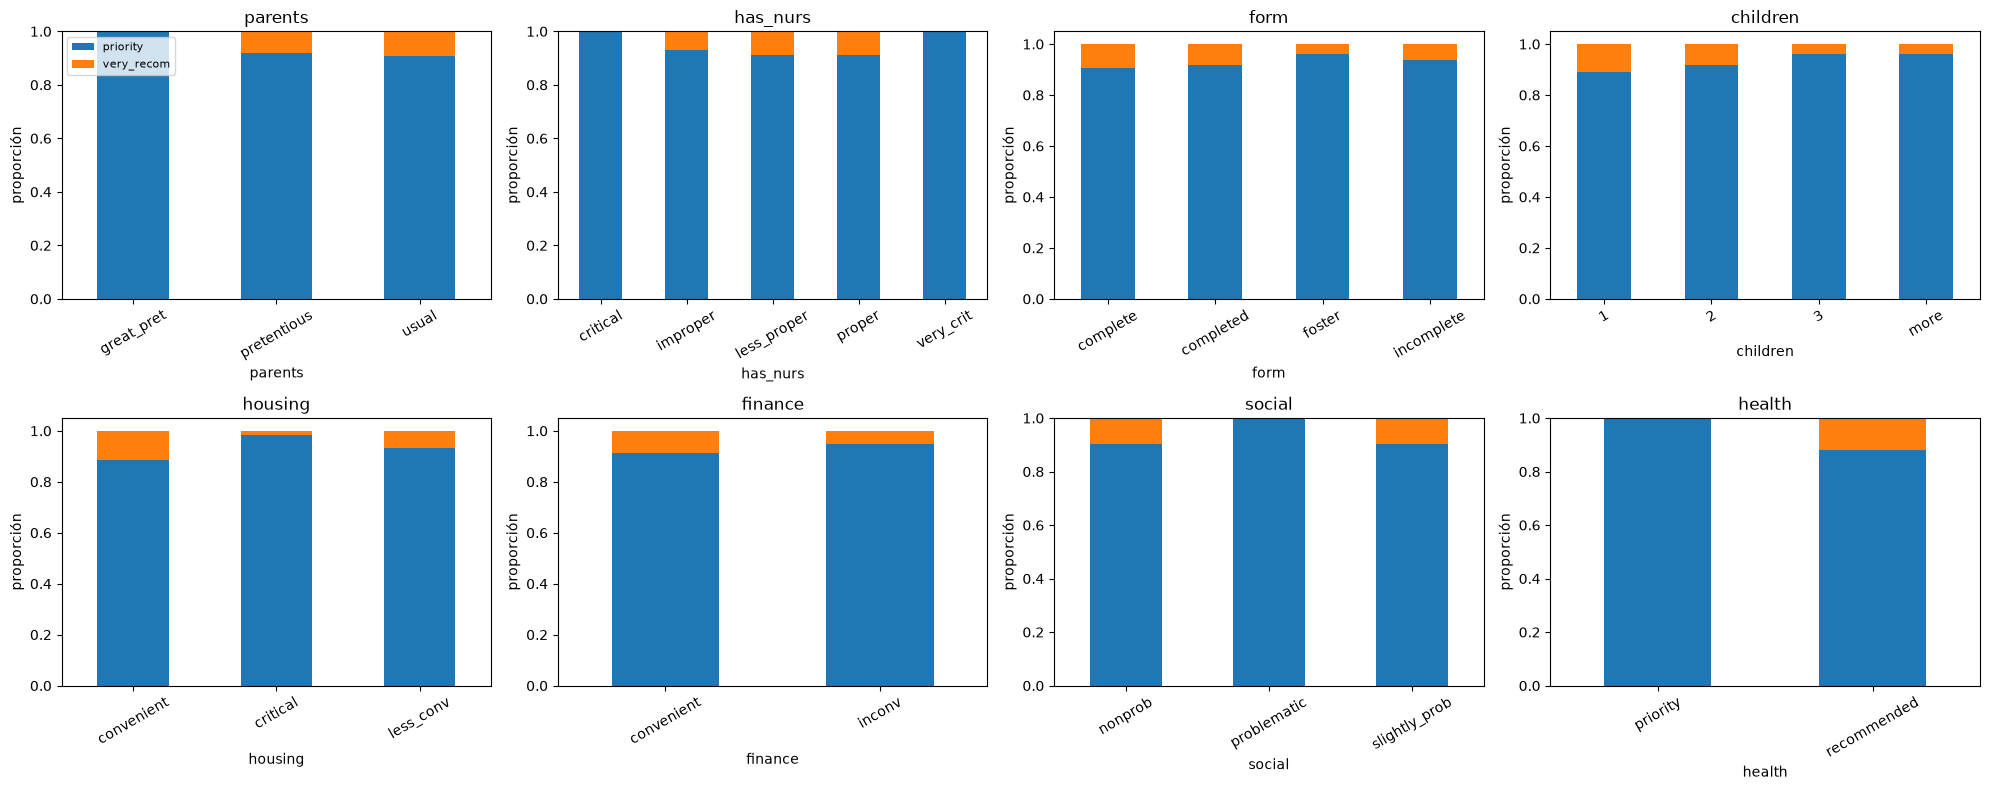

In [29]:
# @title Proporción de "very_recom" para cada valor de cada atributo
fig, axes= plt.subplots(2, 4, figsize=(20, 8))
for col, ax in zip(columnas[:-1], axes.ravel()):
    prop= pd.crosstab(df_bin[col], df_bin['clase'], normalize='index')
    prop.plot(kind='bar', stacked=True, ax=ax, legend=False)
    ax.set_title(col)
    ax.set_ylabel('proporción')
    ax.tick_params(axis='x', rotation=30)
axes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()

In [30]:
# @title Codificación de atributos
ordinales= {
    'parents':  {'usual': 0, 'pretentious': 1, 'great_pret': 2},
    'has_nurs': {'proper': 0, 'less_proper': 1, 'improper': 2, 'critical': 3, 'very_crit': 4},
    'children': {'1': 1, '2': 2, '3': 3, 'more': 4},
    'housing':  {'convenient': 0, 'less_conv': 1, 'critical': 2},
    'finance':  {'convenient': 0, 'inconv': 1},
    'social':   {'nonprob': 0, 'slightly_prob': 1, 'problematic': 2},
    'health':   {'recommended': 0, 'priority': 1, 'not_recom': 2},
}
df_num= df_bin.copy()
for col, mapa in ordinales.items():
    df_num[col]= df_num[col].map(mapa)

df_num= pd.get_dummies(df_num, columns=['form'], prefix='form', dtype=int)   # one-hot
df_num['clase']= (df_num['clase'] == 'very_recom').astype(int)               # very_recom=1, priority=0

X= df_num.drop('clase', axis=1)
y= df_num['clase']
column_names= X.columns
display(X.head())

# Matriz de correlación
fig= px.imshow(df_num.corr().round(2), text_auto=True, color_continuous_scale='RdBu',
               title='Matriz de Correlación')
fig.update_layout(width=850, height=750)
fig.show()

,parents,has_nurs,children,housing,finance,social,health,form_complete,form_completed,form_foster,form_incomplete
1,0,0,1,0,0,0,1,1,0,0,0
4,0,0,1,0,0,1,1,1,0,0,0
6,0,0,1,0,0,2,0,1,0,0,0
7,0,0,1,0,0,2,1,1,0,0,0
9,0,0,1,0,1,0,0,1,0,0,0


In [31]:
# @title Correlación de cada atributo con la clase
corr_clase= X.corrwith(y).sort_values()
print(corr_clase.round(3))

fig= px.bar(corr_clase, orientation='h',
            title='Correlación de cada atributo con la clase (very_recom = 1)',
            labels={'value': 'correlación', 'index': 'atributo'})
fig.update_layout(showlegend=False)
fig.show()

health            -0.228
housing           -0.154
social            -0.142
parents           -0.118
children          -0.113
has_nurs          -0.103
finance           -0.072
form_foster       -0.067
form_incomplete   -0.018
form_completed     0.029
form_complete      0.052
dtype: float64


In [33]:
# @title Guardar el subconjunto para los puntos siguientes
df_num.to_csv('nursery_priority_vs_very_recom.csv', index=False)
print(f"Guardado: nursery_priority_vs_very_recom.csv ({df_num.shape[0]} filas, {df_num.shape[1]} columnas)")
print("Clase: 1 = very_recom, 0 = priority")

Guardado: nursery_priority_vs_very_recom.csv (4594 filas, 12 columnas)
Clase: 1 = very_recom, 0 = priority


In [ ]:
# @title Pearson vs Spearman vs Distancia: datos de ejemplo
from scipy.stats import pearsonr, spearmanr

def corr_distancia(x, y):
    x = np.asarray(x, dtype=np.float32)
    y = np.asarray(y, dtype=np.float32)
    # distancia entre todos los pares de puntos
    a = np.abs(x[:, None] - x)
    b = np.abs(y[:, None] - y)
    # centrado doble: le resta el promedio de filas y columnas
    A = a - a.mean(axis=0) - a.mean(axis=1)[:, None] + a.mean()
    B = b - b.mean(axis=0) - b.mean(axis=1)[:, None] + b.mean()
    return float(np.sqrt((A * B).mean() / np.sqrt((A * A).mean() * (B * B).mean())))

rng = np.random.default_rng(SEMILLA)
x = np.arange(5, 55, 5, dtype=float)
ruido = rng.normal(0, 3, size=x.size)

y_recta = 40 + 0.7 * x + ruido
y_atipico = y_recta.copy()
y_atipico[1] = 170                              # un solo punto atípico
y_curva = -0.1 * (x - 27.5) ** 2 + 60 + ruido   # sube y después baja

casos = {"Recta": y_recta, "Recta + un punto atípico": y_atipico, "U invertida": y_curva}

fig, ejes = plt.subplots(1, 3, figsize=(14, 4))
for eje, (nombre, y) in zip(ejes, casos.items()):
    r = pearsonr(x, y)[0]
    rho = spearmanr(x, y)[0]
    d = corr_distancia(x, y)
    eje.scatter(x, y)
    eje.set_title(f"{nombre}\nPearson={r:.2f} | Spearman={rho:.2f} | Distancia={d:.2f}")
    eje.set_xlabel("x")
    eje.set_ylabel("y")
plt.tight_layout()
plt.show()

,Pearson,Spearman,Distancia
atributo,,,
health,-0.228,-0.228,0.228
housing,-0.154,-0.154,0.150
social,-0.142,-0.138,0.144
parents,-0.118,-0.110,0.114
children,-0.113,-0.114,0.113
has_nurs,-0.103,-0.092,0.100
form,-0.078,-0.077,0.076
finance,-0.072,-0.072,0.072


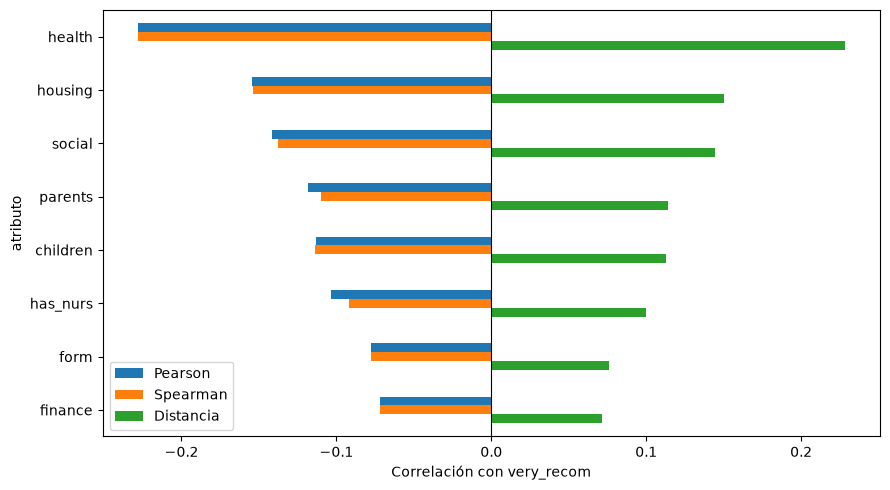

In [35]:
# @title Correlación de cada atributo con very_recom
orden = {
    'parents':  ['usual', 'pretentious', 'great_pret'],
    'has_nurs': ['proper', 'less_proper', 'improper', 'critical', 'very_crit'],
    'form':     ['complete', 'completed', 'incomplete', 'foster'],
    'children': ['1', '2', '3', 'more'],
    'housing':  ['convenient', 'less_conv', 'critical'],
    'finance':  ['convenient', 'inconv'],
    'social':   ['nonprob', 'slightly_prob', 'problematic'],
    'health':   ['recommended', 'priority', 'not_recom'],
}

datos = df[df['clase'].isin(['priority', 'very_recom'])]
# cada categoría pasa a ser su posición en la lista
num = pd.DataFrame({c: datos[c].map({v: i for i, v in enumerate(vals)}) for c, vals in orden.items()})
y = (datos['clase'] == 'very_recom').astype(int)

filas = []
for c in num.columns:
    filas.append({'atributo': c,
                  'Pearson': pearsonr(num[c], y)[0],
                  'Spearman': spearmanr(num[c], y)[0],
                  'Distancia': corr_distancia(num[c], y)})

res = pd.DataFrame(filas).set_index('atributo').sort_values('Distancia', ascending=False)
display(res.round(3))

res.plot.barh(figsize=(9, 5))
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel("Correlación con very_recom")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

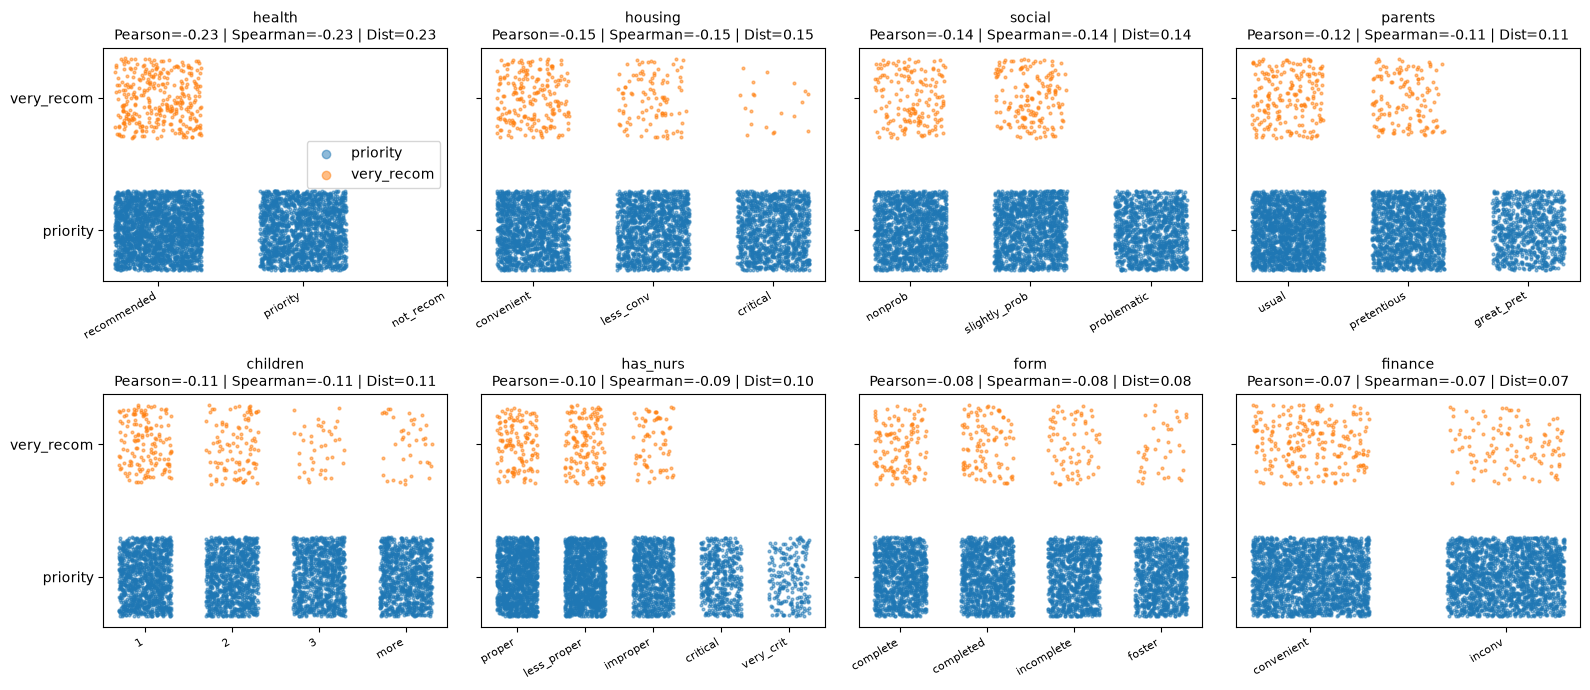

In [36]:
# @title Gráficos de puntos: cada atributo contra la clase
clase_num = (datos['clase'] == 'very_recom').astype(int).to_numpy()
rng = np.random.default_rng(SEMILLA)

fig, ejes = plt.subplots(2, 4, figsize=(16, 7), sharey=True)

for eje, c in zip(ejes.ravel(), res.index):
    # jitter: mueve cada punto un poquito al azar para que no queden todos encimados
    x_jit = num[c].to_numpy() + rng.uniform(-0.3, 0.3, len(num))
    y_jit = clase_num + rng.uniform(-0.3, 0.3, len(num))

    for valor, color, nombre in [(0, 'tab:blue', 'priority'), (1, 'tab:orange', 'very_recom')]:
        filtro = clase_num == valor
        eje.scatter(x_jit[filtro], y_jit[filtro], s=4, alpha=0.5, color=color, label=nombre)

    eje.set_title(f"{c}\nPearson={res.loc[c, 'Pearson']:.2f} | Spearman={res.loc[c, 'Spearman']:.2f} | Dist={res.loc[c, 'Distancia']:.2f}", fontsize=10)
    eje.set_xticks(range(len(orden[c])))
    eje.set_xticklabels(orden[c], rotation=30, ha='right', fontsize=8)
    eje.set_yticks([0, 1])
    eje.set_yticklabels(['priority', 'very_recom'])

ejes[0, 0].legend(markerscale=3, loc='center right')
plt.tight_layout()
plt.show()
